In [1]:
import pandas as pd
import re

TRAIN_FILE = '/kaggle/input/datasets/shadabhussain/flickr8k/Flickr_Data/Flickr_Data/Flickr_TextData/Flickr8k.lemma.token.txt'
rows = []
with open(TRAIN_FILE) as f:
    for line in f:
        line = line.strip()
        if not line or '\t' not in line:
            continue
        img_part, caption = line.split('\t', 1)
        img_name = img_part.split('#')[0]  # strip the #0, #1, etc.
        rows.append((img_name, caption))

df = pd.DataFrame(rows, columns=['image', 'caption'])

def clean(text):
    text = text.lower()
    text = re.sub(r'[^a-z ]', '', text)
    return text.strip()

df['caption'] = df['caption'].apply(clean)
df['caption'] = df['caption'].apply(lambda c: 'startseq ' + c + ' endseq')

all_words = ' '.join(df['caption']).split()
vocab = sorted(set(all_words))
word2idx = {w: i+1 for i, w in enumerate(vocab)}
idx2word = {i+1: w for i, w in enumerate(vocab)}
vocab_size = len(vocab) + 1
print(f"Vocab size: {vocab_size}, Samples: {len(df)}")

df = df.sample(3000, random_state=42).reset_index(drop=True)

Vocab size: 6704, Samples: 40460


In [2]:
import os; [print(root) or print(files[:5]) for root, dirs, files in os.walk('/kaggle/input') if files][:0]

/kaggle/input/datasets/shadabhussain/flickr8k
['model_weights.h5', 'train_encoded_images.p']
/kaggle/input/datasets/shadabhussain/flickr8k/Flickr_Data/Flickr_Data/flickr8ktextfiles
['flickr_8k_train_dataset.txt', 'flickr_8k_val_dataset.txt']
/kaggle/input/datasets/shadabhussain/flickr8k/Flickr_Data/Flickr_Data/Flickr_TextData
['ExpertAnnotations.txt', 'readme.txt', 'Flickr_8k.devImages.txt', 'Flickr8k.lemma.token.txt', 'Flickr_8k.testImages.txt']
/kaggle/input/datasets/shadabhussain/flickr8k/Flickr_Data/Flickr_Data/Images
['3226254560_2f8ac147ea.jpg', '214543992_ce6c0d9f9b.jpg', '2366643786_9c9a830db8.jpg', '3368819708_0bfa0808f8.jpg', '2190227737_6e0bde2623.jpg']
/kaggle/input/datasets/shadabhussain/flickr8k/flickr_data/Flickr_Data/flickr8ktextfiles
['flickr_8k_train_dataset.txt', 'flickr_8k_val_dataset.txt']
/kaggle/input/datasets/shadabhussain/flickr8k/flickr_data/Flickr_Data/Flickr_TextData
['ExpertAnnotations.txt', 'readme.txt', 'Flickr_8k.devImages.txt', 'Flickr8k.lemma.token.txt

[]

In [3]:
TRAIN_FILE = '/kaggle/input/datasets/shadabhussain/flickr8k/Flickr_Data/Flickr_Data/Flickr_TextData/Flickr8k.lemma.token.txt'
import os
print(os.path.getsize(TRAIN_FILE))

3244761


In [4]:
import torch
import torchvision.models as models
import torchvision.transforms as T
from PIL import Image
import os

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
resnet = models.resnet18(pretrained=True)
resnet = torch.nn.Sequential(*list(resnet.children())[:-2])  # keep spatial feature map (B,512,7,7)
resnet = resnet.to(device).eval()

transform = T.Compose([
    T.Resize((224,224)), T.ToTensor(),
    T.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
])

IMG_DIR = '/kaggle/input/datasets/shadabhussain/flickr8k/Flickr_Data/Flickr_Data/Images'
def extract_features(img_name):
    img = Image.open(os.path.join(IMG_DIR, img_name)).convert('RGB')
    x = transform(img).unsqueeze(0).to(device)
    with torch.no_grad():
        feat = resnet(x)  # (1, 512, 7, 7)
    return feat.squeeze(0).cpu()  # (512, 7, 7)

# Cache features for unique images (takes a few minutes)
unique_imgs = df['image'].unique()
features = {}
for i, img_name in enumerate(unique_imgs):
    features[img_name] = extract_features(img_name)
    if i % 200 == 0:
        print(f"{i}/{len(unique_imgs)}")

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 202MB/s]


0/2598
200/2598
400/2598
600/2598
800/2598
1000/2598
1200/2598
1400/2598
1600/2598
1800/2598
2000/2598
2200/2598
2400/2598


In [5]:
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

MAX_LEN = 25

class CaptionDataset(Dataset):
    def __init__(self, df, features):
        self.df = df
        self.features = features
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        feat = self.features[row['image']]  # (512,7,7)
        tokens = row['caption'].split()[:MAX_LEN]
        indices = torch.tensor([word2idx[w] for w in tokens], dtype=torch.long)
        return feat, indices

def collate_fn(batch):
    feats, caps = zip(*batch)
    feats = torch.stack(feats)
    caps_padded = pad_sequence(caps, batch_first=True, padding_value=0)
    return feats, caps_padded

train_loader = DataLoader(CaptionDataset(df, features), batch_size=32, shuffle=True, collate_fn=collate_fn)

In [6]:
import torch.nn as nn

class Attention(nn.Module):
    def __init__(self, feat_dim=512, hidden_dim=256):
        super().__init__()
        self.attn = nn.Linear(feat_dim + hidden_dim, 49)  # 49 = 7x7 spatial locations
    def forward(self, features, hidden):
        # features: (B, 49, 512), hidden: (B, hidden_dim)
        h_rep = hidden.unsqueeze(1).repeat(1, 49, 1)
        scores = self.attn(torch.cat([features, h_rep], dim=2)).mean(dim=2)  # (B,49)
        weights = torch.softmax(scores, dim=1)
        context = (features * weights.unsqueeze(2)).sum(dim=1)  # (B, 512)
        return context, weights

class Captioner(nn.Module):
    def __init__(self, vocab_size, embed_dim=256, hidden_dim=256, feat_dim=512):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, embed_dim)
        self.attention = Attention(feat_dim, hidden_dim)
        self.lstm = nn.LSTMCell(embed_dim + feat_dim, hidden_dim)
        self.fc = nn.Linear(hidden_dim, vocab_size)
        self.init_h = nn.Linear(feat_dim, hidden_dim)
        self.init_c = nn.Linear(feat_dim, hidden_dim)

    def forward(self, features, captions):
        B = features.size(0)
        features = features.view(B, 512, 49).permute(0,2,1)  # (B,49,512)
        mean_feat = features.mean(dim=1)
        h = self.init_h(mean_feat)
        c = self.init_c(mean_feat)

        embeds = self.embed(captions)  # (B, T, embed_dim)
        T_len = captions.size(1)
        outputs = torch.zeros(B, T_len, self.fc.out_features).to(features.device)

        for t in range(T_len):
            context, _ = self.attention(features, h)
            lstm_input = torch.cat([embeds[:, t, :], context], dim=1)
            h, c = self.lstm(lstm_input, (h, c))
            outputs[:, t, :] = self.fc(h)
        return outputs

model = Captioner(vocab_size).to(device)

In [7]:
criterion = nn.CrossEntropyLoss(ignore_index=0)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

losses = []
EPOCHS = 15
model.train()
for epoch in range(EPOCHS):
    epoch_loss = 0
    for feats, caps in train_loader:
        feats, caps = feats.to(device), caps.to(device)
        optimizer.zero_grad()
        outputs = model(feats, caps[:, :-1])  # predict next word
        loss = criterion(outputs.reshape(-1, vocab_size), caps[:, 1:].reshape(-1))
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    avg = epoch_loss / len(train_loader)
    losses.append(avg)
    print(f"Epoch {epoch+1}: loss={avg:.4f}")

Epoch 1: loss=5.2225
Epoch 2: loss=4.1086
Epoch 3: loss=3.6771
Epoch 4: loss=3.3950
Epoch 5: loss=3.1669
Epoch 6: loss=2.9715
Epoch 7: loss=2.7911
Epoch 8: loss=2.6197
Epoch 9: loss=2.4560
Epoch 10: loss=2.2988
Epoch 11: loss=2.1512
Epoch 12: loss=2.0011
Epoch 13: loss=1.8587
Epoch 14: loss=1.7190
Epoch 15: loss=1.5903


In [8]:
from nltk.translate.bleu_score import sentence_bleu
import nltk
nltk.download('punkt', quiet=True)

def generate_caption(feat, max_len=20):
    model.eval()
    feat = feat.unsqueeze(0).to(device)
    feat_r = feat.view(1, 512, 49).permute(0,2,1)
    mean_feat = feat_r.mean(dim=1)
    h = model.init_h(mean_feat)
    c = model.init_c(mean_feat)
    word = torch.tensor([word2idx['startseq']]).to(device)
    result = []
    for _ in range(max_len):
        embed = model.embed(word)
        context, _ = model.attention(feat_r, h)
        h, c = model.lstm(torch.cat([embed, context], dim=1), (h, c))
        out = model.fc(h)
        pred = out.argmax(dim=1).item()
        if idx2word.get(pred) == 'endseq':
            break
        result.append(idx2word.get(pred, ''))
        word = torch.tensor([pred]).to(device)
    return ' '.join(result)

# BLEU on a few val examples
bleu_scores = []
sample_imgs = df['image'].unique()[:20]
for img_name in sample_imgs:
    feat = features[img_name]
    pred_caption = generate_caption(feat)
    refs = df[df['image']==img_name]['caption'].apply(
        lambda c: c.replace('startseq','').replace('endseq','').split()
    ).tolist()
    score = sentence_bleu(refs, pred_caption.split())
    bleu_scores.append(score)

print(f"Avg BLEU: {sum(bleu_scores)/len(bleu_scores):.4f}")
print(f"Example: {generate_caption(features[sample_imgs[0]])}")

Avg BLEU: 0.1125
Example: a dog be swim in a pool


/usr/local/lib/python3.12/dist-packages/nltk/translate/bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 2-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
/usr/local/lib/python3.12/dist-packages/nltk/translate/bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 3-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
/usr/local/lib/python3.12/dist-packages/nltk/translate/bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_

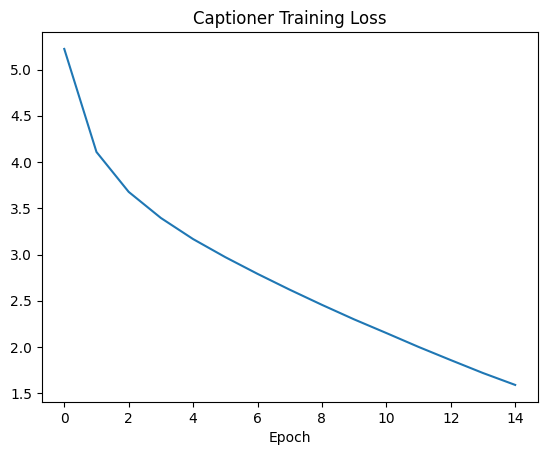

In [9]:
import matplotlib.pyplot as plt
plt.plot(losses); plt.title('Captioner Training Loss'); plt.xlabel('Epoch')
plt.savefig('captioner_loss.png', dpi=150); plt.show()